# 🌸 Аналитика цветочного магазина (розница, Бизнес.Ру)

Этот ноутбук читает **выгрузки из Бизнес.Ру** и кассовые таблицы Excel и отвечает на вопросы:

| # | Вопрос владельца | Раздел |
|---|---|---|
| 1 | Данные вообще правильные? Сходится ли касса с отчётами? | 3 |
| 2 | Сколько мы зарабатываем, какая у нас маржа? | 4 |
| 3 | В какие дни недели и часы у нас продажи? | 5, 8 |
| 4 | Какие товары приносят деньги (ABC-анализ)? | 6 |
| 5 | Где расхождения в кассе, кому и сколько платим? | 7 |
| 6 | Что покупают вместе (чтобы делать букеты и допродажи)? | 9 |
| 7 | Чего не хватает, а что залежалось (цветы портятся!)? | 10 |
| 8 | Сколько продадим в ближайшие дни? | 11 |
| 9 | Готовый Excel-отчёт для сохранения | 12 |

**Как пользоваться:** 1) положите файлы в папку `data/` рядом с ноутбуком; 2) при необходимости поправьте ячейку «Настройки»; 3) нажмите **Kernel → Restart & Run All**. Всё остальное считается само.

## 0. Подключаем библиотеки

Библиотеки — это готовые «наборы инструментов». `pandas` — это Excel внутри Python (таблицы), `matplotlib` и `seaborn` рисуют графики.

In [1]:
import re
import warnings
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 5.5), "axes.titlesize": 14, "axes.titleweight": "bold",
    "font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", "\u202f"))

def rub(x):
    """Красиво показывает деньги: 1234567 -> '1 234 567 ₽'."""
    return f"{x:,.0f} ₽".replace(",", " ")

def fmt_k(x, pos=None):
    """Подписи осей: 150000 -> '150К'."""
    return f"{x/1e6:.1f}М" if abs(x) >= 1e6 else f"{x/1e3:.0f}К"

WEEKDAYS = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
print("✅ Библиотеки готовы")

✅ Библиотеки готовы


## 1. Настройки  ⚙️

**Только эту ячейку нужно править.** Названия файлов — ровно такие, как вы их сохраняете из Бизнес.Ру.

In [2]:
DATA_DIR = Path("data")      # папка с файлами
OUT_DIR  = Path("output")    # сюда сохранится готовый Excel-отчёт
OUT_DIR.mkdir(exist_ok=True)

FILE_SALES     = "Продажи.csv"           # Отчёты → Продажи (итоги по товарам)
FILE_MOVEMENT  = "Движение товаров.csv"  # Отчёты → Движение товара (с документами-чеками); подойдёт и .xls
CASH_GLOB      = "*Контроль*.xlsx"       # ваши кассовые таблицы (по месяцу на файл)
FILE_REALIZ    = "Отчет по реализациям.csv"  # необязательно

# За какой период выгружен отчёт «Продажи»? В нём самих дат нет.
# None = взять период чеков из «Движения товара» (ноутбук сам проверит, что это правда).
# Если хотите задать вручную: ("2026-09-01", "2026-10-09")
SALES_PERIOD = None
EXCLUDE_FROM_BASKET = ["Услуги флориста"]   # услуги «сборки» есть почти в каждом букете и портят анализ связок

TOP_N            = 15   # сколько товаров показывать в топах
MIN_PAIR_COUNT   = 5    # пара товаров должна встретиться хотя бы в стольких чеках
MIN_DAYS_COVER   = 2    # меньше стольких дней запаса = пора докупать
SHELF_LIFE_DAYS  = {"Горшечные растения": 30, "Упаковка и аксессуары": 9999, "Услуги флориста": 9999}
DEFAULT_SHELF    = 7    # срок «жизни» срезки, дней (для остальных категорий)
FORECAST_DAYS    = 14   # на сколько дней вперёд прогноз

## 2. Загрузка данных

Бизнес.Ру отдаёт файлы «для людей», а не «для программ»: в них склеены заголовки, кодировка бывает `cp1251`, числа записаны как `1 234,50` или `8 шт.`, а в «Движении товара» таблица вложена как дерево *(товар → склад → документ)*. Поэтому сначала пишем **функции-переводчики**, которые превращают такие файлы в обычные плоские таблицы.

In [3]:
# ---------- Базовые помощники ----------
def read_csv_smart(path, **kw):
    """Читает CSV из Бизнес.Ру: пробует кодировки utf-8 и cp1251, разделитель ';'. Всё читаем как текст."""
    for enc in ("utf-8-sig", "cp1251"):
        try:
            return pd.read_csv(path, sep=";", encoding=enc, dtype=str, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Не удалось определить кодировку: {path}")

def read_table_any(path):
    """Читает таблицу без заголовка из CSV, XLS или XLSX."""
    path = Path(path)
    if path.suffix.lower() == ".xls":
        return pd.read_excel(path, header=None, dtype=str, engine="xlrd")
    if path.suffix.lower() == ".xlsx":
        return pd.read_excel(path, header=None, dtype=str, engine="openpyxl")
    return read_csv_smart(path, header=None)

def to_num(s):
    """'1 234,50' -> 1234.5 ; '8 шт.' -> 8 ; '16,28%' -> 16.28 ; пусто -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(r"[^\d,.\-]", "", regex=True).str.replace(",", ".", regex=False),
        errors="coerce")

def num(v):
    """То же для одного значения (без ошибок на пустых ячейках)."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return 0.0
    try:
        return float(str(v).replace("\xa0", "").replace(" ", "").replace(",", "."))
    except ValueError:
        return 0.0

# ---------- Категории товаров (правила по названию; при желании дополняйте) ----------
CATEGORY_RULES = [
    ("Услуги флориста",       r"флор\s*услуг"),
    ("Упаковка и аксессуары", r"короб|конверт|открытк|пакет|пакт|сумк|кашпо|оазис|декоратив|кризал|грунт|подкормк|лент"),
    ("Горшечные растения",    r"\d+\s*/\s*\d+|фаленопсис|антуриум|шефлер|спатифилиум|сансивиер|цимбидиум|шлюмбергер|эхиверия|инжир"),
    ("Розы",                  r"(^|\s)роз[аы]($|\s)|кустовая\s+роза"),
    ("Хризантемы",            r"хризантем"),
    ("Зелень и наполнители",  r"эвкалипт|папортник|папоротник|аспидистр|рускус|писташ|лист дуба|гипсофил|лимониум|грин трик|скимия|краспедия|танацетум|брасика|молочай"),
]
def categorize(name):
    n = str(name).lower()
    for cat, pattern in CATEGORY_RULES:
        if re.search(pattern, n):
            return cat
    return "Прочая срезка"

### 2.1 Итоги продаж по товарам (`Отчёты → Продажи`)

In [4]:
def load_sales(path):
    df = read_csv_smart(path)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]          # лишний пустой столбец из-за «;» в конце строки
    df = df.rename(columns={
        "Товар/Услуга": "товар", "Кол-во": "кол_во",
        "Себестоимость. Цена": "себест_цена", "Себестоимость. Сумма": "себестоимость",
        "Выручка. Цена": "цена", "Выручка. Сумма": "выручка",
    })
    df = df[df["товар"].notna() & ~df["товар"].str.contains("итого", case=False, na=False)].copy()
    for c in ["кол_во", "себест_цена", "себестоимость", "цена", "выручка"]:
        df[c] = to_num(df[c])
    df["маржа_руб"] = df["выручка"] - df["себестоимость"]
    df["маржа_pct"] = np.where(df["выручка"] > 0, df["маржа_руб"] / df["выручка"] * 100, np.nan)
    df["категория"] = df["товар"].map(categorize)
    return df[["товар", "категория", "кол_во", "себест_цена", "цена", "себестоимость", "выручка", "маржа_руб", "маржа_pct"]]

sales = load_sales(DATA_DIR / FILE_SALES)
print(f"Товаров в отчёте: {len(sales)}")
sales.head()

Товаров в отчёте: 66


,товар,категория,кол_во,себест_цена,цена,себестоимость,выручка,маржа_руб,маржа_pct
0,Алиум,Прочая срезка,9.00,344.00,400.00,3 096.00,3 600.00,504.00,14.00
1,Альстрамерия,Прочая срезка,98.00,72.93,147.70,7 147.20,14 475.00,7 327.80,50.62
2,Аспидистра,Зелень и наполнители,3.00,23.20,50.00,69.60,150.00,80.40,53.60
3,Банксия,Прочая срезка,3.00,280.00,350.00,840.00,1 050.00,210.00,20.00
4,Брасика,Зелень и наполнители,1.00,102.40,250.00,102.40,250.00,147.60,59.04


### 2.2 Движение товара — самая ценная таблица

В этом отчёте **каждая строка = один товар в одном чеке** (со временем чека и себестоимостью). Из него мы получаем:
* `lines` — плоская таблица «товар × документ» (для часов, корзин, дней);
* `items` — итог по каждому товару: был остаток, пришло, продано, **остаток сейчас**.

In [5]:
DOC_RE = re.compile(r"^(?P<тип>[^№]+?)\s*№\s*(?P<номер>\S+)\s+от\s+(?P<дата>\d{2}\.\d{2}\.\d{4})(?:\s+(?P<время>\d{1,2}:\d{2}))?")

def load_movement(path):
    raw = read_table_any(path)
    # находим строку шапки и пропускаем 2 строки шапки (название колонок + «Количество/Себестоимость/Сумма»)
    start = raw.index[raw[0].astype(str).str.startswith("Наименование")][0] + 2
    item_rows, line_rows = [], []
    product = unit = warehouse = None
    for _, r in raw.iloc[start:].iterrows():
        g = lambda i: r.get(i, np.nan)
        if pd.notna(g(0)):                                   # строка ТОВАРА
            full = str(g(0)).strip()
            m = re.search(r",\s*([^,]+)$", full)
            product, unit = (full[:m.start()].strip(), m.group(1).strip()) if m else (full, "")
            item_rows.append(dict(
                товар=product, ед=unit,
                нач_кол=num(g(4)), приход_кол=num(g(7)), расход_кол=num(g(10)),
                расход_себест=num(g(12)), кон_кол=num(g(13)), кон_себест_ед=num(g(14)), кон_сумма=num(g(15))))
        elif pd.notna(g(1)):                                 # строка СКЛАДА
            warehouse = str(g(1)).strip()
        elif pd.notna(g(2)):                                 # строка ДОКУМЕНТА (чек, поступление, списание...)
            text = str(g(2)).strip()
            m = DOC_RE.match(text)
            if m:
                dt = pd.to_datetime(m["дата"] + " " + (m["время"] or "00:00"), dayfirst=True)
                doc_type, doc_no, has_time = m["тип"].strip(), m["номер"], m["время"] is not None
            else:
                dt, doc_type, doc_no, has_time = pd.NaT, text, "", False
            line_rows.append(dict(
                товар=product, склад=warehouse, док_тип=doc_type, док_номер=doc_no, дата=dt, есть_время=has_time,
                контрагент=g(3) if pd.notna(g(3)) else "",
                приход_кол=num(g(7)), приход_сумма=num(g(9)),
                расход_кол=num(g(10)), себест_ед=num(g(11)), расход_себест=num(g(12))))
    items, lines = pd.DataFrame(item_rows), pd.DataFrame(line_rows)
    lines["кол_во"] = lines["расход_кол"] - lines["приход_кол"]       # чистое количество (возвраты вычитаются)
    lines["категория"] = lines["товар"].map(categorize)
    items["категория"] = items["товар"].map(categorize)
    return items, lines

items, lines = load_movement(DATA_DIR / FILE_MOVEMENT)
checks = lines[lines["док_тип"].str.lower().str.startswith("чек")].copy()
print(f"Товаров: {len(items)} | строк-документов: {len(lines)} | чеков: {checks['док_номер'].nunique()}")
print(f"Период чеков: {checks['дата'].min():%d.%m.%Y} — {checks['дата'].max():%d.%m.%Y}")
print("Типы документов в выгрузке:", dict(lines['док_тип'].value_counts()))
lines.head()

Товаров: 483 | строк-документов: 535 | чеков: 248
Период чеков: 01.10.2026 — 14.10.2026
Типы документов в выгрузке: {'Чек': np.int64(535)}


,товар,склад,док_тип,док_номер,дата,есть_время,контрагент,приход_кол,приход_сумма,расход_кол,себест_ед,расход_себест,кол_во,категория
0,Алиум,Основной склад,Чек,261002171300306249,2026-10-02 17:13:00,True,,0.00,0.00,3.00,344.00,1 032.00,3.00,Прочая срезка
1,Алиум,Основной склад,Чек,261002191800306256,2026-10-02 19:18:00,True,,0.00,0.00,1.00,344.00,344.00,1.00,Прочая срезка
2,Алиум,Основной склад,Чек,261003182500306271,2026-10-03 18:25:00,True,,0.00,0.00,1.00,344.00,344.00,1.00,Прочая срезка
3,Алиум,Основной склад,Чек,261003202700306274,2026-10-03 20:27:00,True,,0.00,0.00,2.00,344.00,688.00,2.00,Прочая срезка
4,Алиум,Основной склад,Чек,261011173200306421,2026-10-11 17:32:00,True,,0.00,0.00,2.00,344.00,688.00,2.00,Прочая срезка


### 2.3 Ваши кассовые таблицы Excel (`Курская_Контроль_*.xlsx`)

Это ваш собственный учёт: выручка по сменам, нал/безнал, расходы, зарплата, остаток кассы. Это **единственный источник дневной выручки**, поэтому он очень важен.

In [6]:
def load_cash(paths):
    daily, per_emp = [], []
    for p in sorted(paths):
        raw = pd.read_excel(p, sheet_name="Касса", header=None)
        hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq("Дата")][0]
        df = raw.iloc[hdr + 1:].copy()
        df.columns = [str(c).strip() for c in raw.iloc[hdr]]
        df = df[pd.to_datetime(df["Дата"], errors="coerce").notna()].copy()
        N = lambda name: pd.to_numeric(df[name], errors="coerce").fillna(0) if name in df.columns else 0.0

        employees = [c[len("Итого "):] for c in df.columns if c.startswith("Итого ")]
        d = pd.DataFrame({"дата": pd.to_datetime(df["Дата"]).values, "смена": df["Смена"].values})
        d["нал"], d["безнал"] = 0.0, 0.0
        for e in employees:
            nal, bez = N(f"Наличка {e}").values, N(f"Безнал {e}").values
            d["нал"] += nal; d["безнал"] += bez
            per_emp.append(pd.DataFrame({"дата": d["дата"], "сотрудник": e, "нал": nal, "безнал": bez,
                                         "выручка": nal + bez, "зп": N(f"ЗП {e} (начислено)").values}))
        d["выручка"]        = d["нал"] + d["безнал"]
        d["расход_нал"]     = N("Расход (нал)").values
        d["внесено"]        = N("Внесено доп. в кассу (нал)").values
        d["изъято"]         = N("Изъято из кассы (нал)").values
        d["зп_начислено"]   = sum(N(f"ЗП {e} (начислено)").values for e in employees)
        d["остаток_расчёт"] = N("Остаток вечером (расчёт)").values
        d["остаток_факт"]   = N("Остаток вечером (факт)").values
        d["разница"]        = N("Разница").values
        d["статус"]         = df["Статус"].values
        daily.append(d)
    cash = pd.concat(daily, ignore_index=True)
    cash = cash[cash["выручка"] > 0].sort_values("дата").reset_index(drop=True)   # убираем незаполненные будущие дни
    cash["день_недели"] = cash["дата"].dt.dayofweek.map(dict(enumerate(WEEKDAYS)))
    cash["месяц"] = cash["дата"].dt.to_period("M").astype(str)
    emp = pd.concat(per_emp, ignore_index=True)
    emp = emp[emp["выручка"] > 0].reset_index(drop=True)
    return cash, emp

cash_files = sorted(DATA_DIR.glob(CASH_GLOB))
print("Кассовые файлы:", [f.name for f in cash_files])
cash, cash_emp = load_cash(cash_files)
print(f"Дней с продажами: {len(cash)} | с {cash['дата'].min():%d.%m.%Y} по {cash['дата'].max():%d.%m.%Y}")
cash.head()

Кассовые файлы: ['Курская_Контроль_Октябрь.xlsx']
Дней с продажами: 13 | с 01.10.2026 по 13.10.2026


,дата,смена,нал,безнал,выручка,расход_нал,внесено,изъято,зп_начислено,остаток_расчёт,остаток_факт,разница,статус,день_недели,месяц
0,2026-10-01,Ирина,200.00,35 390.00,35 590.00,0.00,0.00,0.00,5 279.50,15250,15 250.00,0.00,✅ ВСЁ ТОЧНО,Чт,2026-10
1,2026-10-02,Ирина,6 300.00,34 545.00,40 845.00,0.00,0.00,20 000.00,5 542.25,1550,1 550.00,0.00,✅ ВСЁ ТОЧНО,Пт,2026-10
2,2026-10-03,Татьяна,12 000.00,12 400.00,24 400.00,0.00,0.00,0.00,4 720.00,8830,8 830.00,0.00,✅ ВСЁ ТОЧНО,Сб,2026-10
3,2026-10-04,Татьяна,17 150.00,12 400.00,29 550.00,0.00,0.00,0.00,4 977.50,21000,21 000.00,0.00,✅ ВСЁ ТОЧНО,Вс,2026-10
4,2026-10-05,Ирина,4 050.00,48 740.00,52 790.00,0.00,0.00,0.00,6 139.50,25050,25 050.00,0.00,✅ ВСЁ ТОЧНО,Пн,2026-10


## 3. Проверка качества данных 🔍

**Правило №1 в Data Science: сначала проверяем данные, потом делаем выводы.** Мусор на входе — мусор на выходе. Здесь ищем типичные проблемы и сверяем источники друг с другом.

In [7]:
problems = []

# 0) За какой период выгружен «Продажи»? Дат в нём нет. Проверяем: если количество КАЖДОГО товара
#    совпадает с количеством в чеках из «Движения товара» — значит, период тот же.
sold_checks = checks.groupby("товар")["кол_во"].sum()
cmpq = sales.set_index("товар")[["кол_во"]].join(sold_checks.rename("чеки")).fillna(0)
same_period = bool((cmpq["кол_во"] - cmpq["чеки"]).abs().max() < 1e-6)
if SALES_PERIOD is None:
    p0, p1 = checks["дата"].min().normalize(), checks["дата"].max().normalize()
else:
    p0, p1 = pd.Timestamp(SALES_PERIOD[0]), pd.Timestamp(SALES_PERIOD[1])
print(f"Количество в «Продажи» совпадает с чеками в «Движении товара»: {'ДА' if same_period else 'НЕТ'}")
print(f"Период анализа: {p0:%d.%m.%Y} — {p1:%d.%m.%Y}\n")
if not same_period:
    problems.append("Количество в отчёте «Продажи» не совпадает с чеками из «Движения товара» — выгрузите оба отчёта за одинаковые даты.")

# 1) Товары с нулевой себестоимостью -> маржа 100% (ошибка учёта: не проставлена закупка)
zero_cost = sales[(sales["себестоимость"] == 0) & (sales["выручка"] > 0)]
if len(zero_cost):
    problems.append(f"Нулевая себестоимость у {len(zero_cost)} товаров: {', '.join(zero_cost['товар'])}. "
                    f"Их маржа завышена на {rub(zero_cost['выручка'].sum())}.")

# 2) Продажи ниже себестоимости
neg = sales[sales["маржа_руб"] < 0]
if len(neg):
    problems.append(f"Продажи ниже себестоимости: {', '.join(neg['товар'])} (убыток {rub(-neg['маржа_руб'].sum())}).")

# 3) Сверка: выручка Бизнес.Ру («Продажи») vs ваша касса за тот же период
cash_period = cash[(cash["дата"] >= p0) & (cash["дата"] <= p1)]["выручка"].sum()
br_rev = sales["выручка"].sum()
diff = br_rev - cash_period
print(f"Выручка по Бизнес.Ру  : {rub(br_rev)}")
print(f"Выручка по вашей кассе: {rub(cash_period)}")
print(f"Расхождение           : {rub(diff)}  ({diff / cash_period * 100:+.1f}% от кассы)")
if abs(diff / cash_period) > 0.01:
    problems.append(f"Выручка в Бизнес.Ру на {rub(-diff)} ({-diff / cash_period:.0%}) меньше, чем в вашей кассовой таблице. "
                    f"Возможные причины: часть продаж не пробита в программе, предоплаты/доставка/онлайн-платежи учтены только в таблице, "
                    f"возвраты, ошибки ввода в таблице.")

# 4) Чеки без времени
no_time = (~checks.drop_duplicates("док_номер")["есть_время"]).mean()
if no_time > 0:
    problems.append(f"У {no_time:.1%} чеков в выгрузке нет времени — в почасовом анализе они пропущены.")

# 5) Отрицательные остатки
neg_stock = items[items["кон_кол"] < 0]
if len(neg_stock):
    problems.append(f"Отрицательный остаток у {len(neg_stock)} товаров (продали раньше, чем оприходовали): {', '.join(neg_stock['товар'].head(8))}.")

# 6) «Скрытый» расход: итог по товару в программе больше, чем сумма документов в списке
doc_out = lines.groupby("товар")[["расход_кол", "расход_себест"]].sum()
hid = items.set_index("товар")[["категория", "расход_кол", "расход_себест"]].join(doc_out, rsuffix="_в_документах").fillna(0)
hid["скрыто_шт"] = hid["расход_кол"] - hid["расход_кол_в_документах"]
hid["скрыто_руб"] = hid["расход_себест"] - hid["расход_себест_в_документах"]
tot_out, tot_hid = items["расход_кол"].sum(), hid["скрыто_шт"].sum()
if tot_hid > 0.05 * tot_out:
    problems.append(f"Со склада ушло {tot_out:.0f} шт., а в списке документов видно {tot_out - tot_hid:.0f} шт. "
                    f"«Невидимый» расход: {tot_hid:.0f} шт. ({tot_hid / tot_out:.0%}) на {rub(hid['скрыто_руб'].sum())} по себестоимости. "
                    f"Это списания / комплектации / перемещения — выгрузите «Движение товара» со ВСЕМИ типами документов.")
print("\nТипы документов в выгрузке:", dict(lines["док_тип"].value_counts()))
print("\nТоп-10 товаров по «невидимому» расходу (по себестоимости):")
display(hid.sort_values("скрыто_руб", ascending=False).head(10)[["категория", "расход_кол", "расход_кол_в_документах", "скрыто_шт", "скрыто_руб"]])

print("\n" + ("⚠️ НАЙДЕНО:\n - " + "\n - ".join(problems) if problems else "✅ Проблем не найдено"))

Количество в «Продажи» совпадает с чеками в «Движении товара»: ДА
Период анализа: 01.10.2026 — 14.10.2026

Выручка по Бизнес.Ру  : 424 903 ₽
Выручка по вашей кассе: 453 343 ₽
Расхождение           : -28 440 ₽  (-6.3% от кассы)

Типы документов в выгрузке: {'Чек': np.int64(535)}

Топ-10 товаров по «невидимому» расходу (по себестоимости):


,категория,расход_кол,расход_кол_в_документах,скрыто_шт,скрыто_руб
товар,,,,,
Георгины,Прочая срезка,168.00,48.00,120.00,14 280.00
Хризантема одноголовая К,Хризантемы,289.00,234.00,55.00,7 700.00
Писташ банч,Зелень и наполнители,105.00,1.00,104.00,7 018.97
Тюльпан пион,Прочая срезка,75.00,0.00,75.00,6 975.00
Роза микс,Розы,140.00,189.00,-49.00,5 392.10
Роза кустовая 60 см. Р,Розы,87.00,40.00,47.00,5 371.16
Хризантема кустовая,Хризантемы,143.00,83.00,60.00,5 098.33
Кустовая роза 50 см. Р,Розы,71.00,0.00,71.00,5 079.00
Гортензия К,Прочая срезка,67.00,49.00,18.00,3 908.80



⚠️ НАЙДЕНО:
 - Нулевая себестоимость у 2 товаров: Грунт для декоративно-лиственных 5л, Оксипеталум. Их маржа завышена на 1 700 ₽.
 - Продажи ниже себестоимости: Оазис, Пленка 1кг (убыток 687 ₽).
 - Выручка в Бизнес.Ру на 28 440 ₽ (6%) меньше, чем в вашей кассовой таблице. Возможные причины: часть продаж не пробита в программе, предоплаты/доставка/онлайн-платежи учтены только в таблице, возвраты, ошибки ввода в таблице.
 - У 2.0% чеков в выгрузке нет времени — в почасовом анализе они пропущены.
 - Отрицательный остаток у 1 товаров (продали раньше, чем оприходовали): Роза микс.


## 4. Ключевые показатели (KPI)

* **Выручка** — сколько получили денег. **Маржа** = выручка − себестоимость (сколько осталось после покупки цветов).
* **Средний чек** = выручка ÷ число чеков. Считаем по месяцам, где есть и касса, и чеки.

In [8]:
rev, cost = sales["выручка"].sum(), sales["себестоимость"].sum()
n_checks = checks["док_номер"].nunique()
cash_total = cash[(cash["дата"] >= p0) & (cash["дата"] <= p1)]["выручка"].sum()
kpi = {
    "Выручка (Бизнес.Ру, «Продажи»)": rub(rev),
    "Выручка по вашей кассе (тот же период)": rub(cash_total),
    "Себестоимость": rub(cost),
    "Валовая прибыль (маржа)": rub(rev - cost),
    "Маржа, %": f"{(rev - cost) / rev * 100:.1f}%",
    "Наценка, % (на себестоимость)": f"{(rev - cost) / cost * 100:.0f}%",
    "Чеков": f"{n_checks}",
    "Средний чек (Бизнес.Ру)": rub(rev / n_checks),
    "Средний чек (если считать по кассе)": rub(cash_total / n_checks),
    "Доля услуг флориста в выручке": f"{sales.loc[sales['категория'] == 'Услуги флориста', 'выручка'].sum() / rev:.1%}",
}
display(pd.Series(kpi, name="Значение").to_frame())

# По месяцам (по вашей кассе)
chk_m = checks.drop_duplicates("док_номер").assign(месяц=lambda d: d["дата"].dt.to_period("M").astype(str)).groupby("месяц").size()
month = cash.groupby("месяц").agg(дней=("дата", "nunique"), выручка=("выручка", "sum"), нал=("нал", "sum"), безнал=("безнал", "sum"))
month["чеков_в_Бизнес.Ру"] = chk_m
month["выручка_в_день"] = month["выручка"] / month["дней"]
month["чеков_в_день"] = month["чеков_в_Бизнес.Ру"] / month["дней"]
month["доля_безнал_%"] = month["безнал"] / month["выручка"] * 100
display(month)
print("⚠️ Неполный месяц сравнивайте по колонкам «в день», а не по сумме.")
print("«Средний чек (Бизнес.Ру)» надёжнее: он считается по одним и тем же документам. Кассовый вариант завышен, пока не объяснено расхождение из раздела 3.")

,Значение
"Выручка (Бизнес.Ру, «Продажи»)",424 903 ₽
Выручка по вашей кассе (тот же период),453 343 ₽
Себестоимость,205 778 ₽
Валовая прибыль (маржа),219 125 ₽
"Маржа, %",51.6%
"Наценка, % (на себестоимость)",106%
Чеков,248
Средний чек (Бизнес.Ру),1 713 ₽
Средний чек (если считать по кассе),1 828 ₽
Доля услуг флориста в выручке,6.4%


,дней,выручка,нал,безнал,чеков_в_Бизнес.Ру,выручка_в_день,чеков_в_день,доля_безнал_%
месяц,,,,,,,,
2026-10,13,453 343.00,87 630.00,365 713.00,248,34 872.54,19.08,80.67


⚠️ Неполный месяц сравнивайте по колонкам «в день», а не по сумме.
«Средний чек (Бизнес.Ру)» надёжнее: он считается по одним и тем же документам. Кассовый вариант завышен, пока не объяснено расхождение из раздела 3.


## 5. Динамика выручки и дни недели 📅

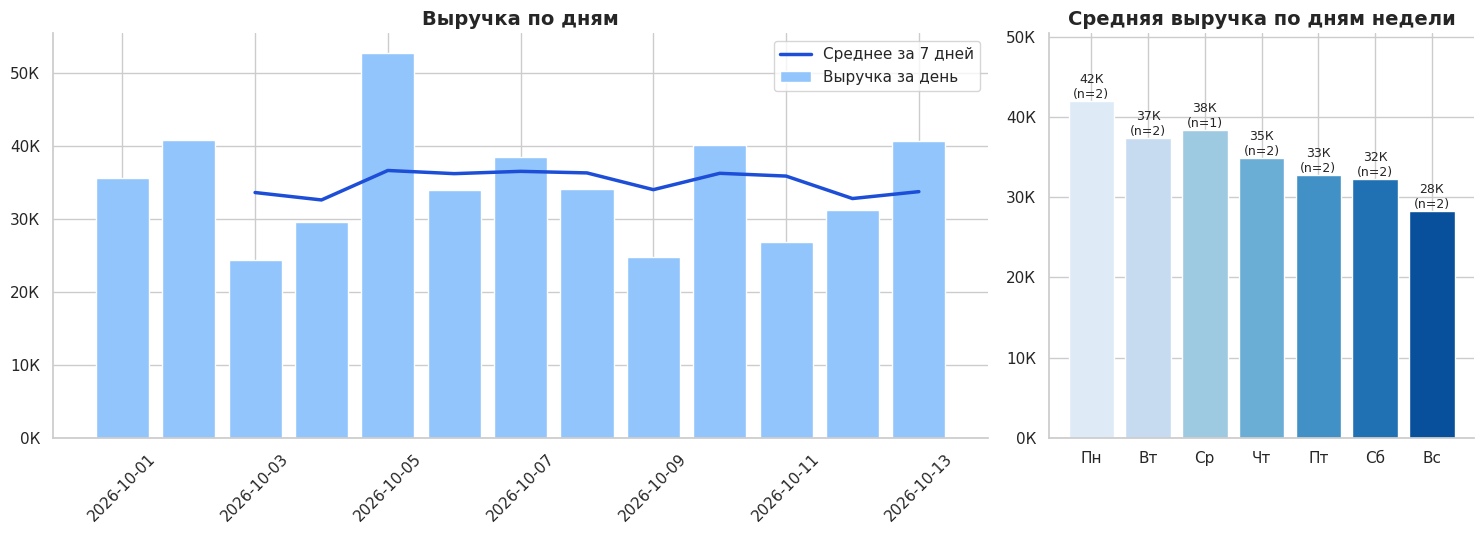

Самый сильный день: Пн (42 020 ₽), самый слабый: Вс (28 218 ₽).
n — сколько таких дней в данных. Пока n мало (<8), выводы предварительные.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})

ax = axes[0]
ax.bar(cash["дата"], cash["выручка"], color="#93C5FD", label="Выручка за день")
ax.plot(cash["дата"], cash["выручка"].rolling(7, min_periods=3).mean(), color="#1D4ED8", lw=2.5, label="Среднее за 7 дней")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_k))
ax.set_title("Выручка по дням"); ax.legend(); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
wd = cash.groupby("день_недели")["выручка"].agg(["mean", "count"]).reindex(WEEKDAYS)
bars = ax.bar(wd.index, wd["mean"], color=sns.color_palette("Blues", 7))
for b, (m, n) in zip(bars, wd[["mean", "count"]].values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{m/1e3:.0f}К\n(n={int(n)})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, wd["mean"].max() * 1.2); ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_k)); ax.set_title("Средняя выручка по дням недели")
plt.tight_layout(); plt.show()

best, worst = wd["mean"].idxmax(), wd["mean"].idxmin()
print(f"Самый сильный день: {best} ({rub(wd.loc[best, 'mean'])}), самый слабый: {worst} ({rub(wd.loc[worst, 'mean'])}).")
print("n — сколько таких дней в данных. Пока n мало (<8), выводы предварительные.")

## 6. ABC-анализ товаров 🏆

Идея Парето: **~20% товаров дают ~80% денег.**
* **A** — товары, дающие первые 80% выручки (их нельзя терять с полки!);
* **B** — следующие 15%; **C** — «хвост» (последние 5%).

Делаем два разреза: по **выручке** и по **марже** (прибыли). Они могут отличаться: товар может быть оборотным, но малодоходным.

,Товаров,"Доля выручки, %","Доля прибыли, %"
класс,,,
A,15,81.03,79.82
B,18,14.07,15.23
C,33,4.90,4.96


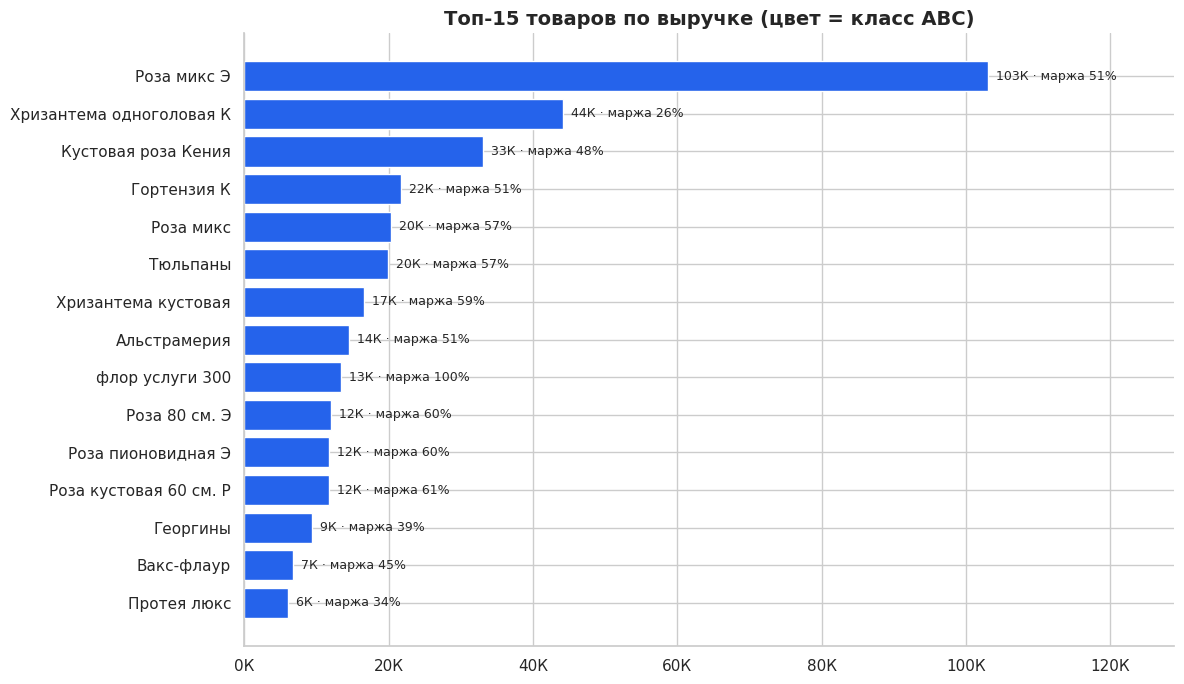

Класс A — всего 15 товаров из 66: именно их наличие определяет выручку.


In [10]:
def abc(df, col):
    d = df.sort_values(col, ascending=False).copy()
    d["доля_%"] = d[col] / d[col].sum() * 100
    d["накопл_%"] = d["доля_%"].cumsum()
    d["класс"] = np.where(d["накопл_%"] - d["доля_%"] < 80, "A", np.where(d["накопл_%"] - d["доля_%"] < 95, "B", "C"))
    return d

abc_rev = abc(sales, "выручка")
abc_mar = abc(sales, "маржа_руб")
summary = pd.DataFrame({
    "Товаров": abc_rev["класс"].value_counts().sort_index(),
    "Доля выручки, %": abc_rev.groupby("класс")["доля_%"].sum(),
    "Доля прибыли, %": abc_rev.groupby("класс")["маржа_руб"].sum() / sales["маржа_руб"].sum() * 100,
})
display(summary)

top = abc_rev.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 7))
colors = top["класс"].map({"A": "#2563EB", "B": "#F59E0B", "C": "#9CA3AF"})
ax.barh(top["товар"], top["выручка"], color=colors)
for y, (v, m) in enumerate(zip(top["выручка"], top["маржа_pct"])):
    ax.text(v, y, f"  {v/1e3:.0f}К · маржа {m:.0f}%", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_k)); ax.set_xlim(0, top["выручка"].max() * 1.25)
ax.set_title(f"Топ-{TOP_N} товаров по выручке (цвет = класс ABC)")
plt.tight_layout(); plt.show()

print(f"Класс A — всего {int((abc_rev['класс']=='A').sum())} товаров из {len(abc_rev)}: именно их наличие определяет выручку.")

### 6.1 Категории и «звёзды / собаки» (выручка × маржа)

,выручка,себестоимость,товаров,маржа_руб,маржа_%,доля_выручки_%
категория,,,,,,
Розы,193 542.50,90 724.89,7,102 817.61,53.12,45.55
Прочая срезка,118 745.00,63 217.40,28,55 527.60,46.76,27.95
Хризантемы,63 390.00,40 632.00,3,22 758.00,35.90,14.92
Услуги флориста,27 060.00,155.00,5,26 905.00,99.43,6.37
Зелень и наполнители,14 568.00,7 733.45,10,6 834.55,46.91,3.43
Упаковка и аксессуары,5 497.50,2 147.56,11,3 349.94,60.94,1.29
Горшечные растения,2 100.00,1 168.00,2,932.00,44.38,0.49


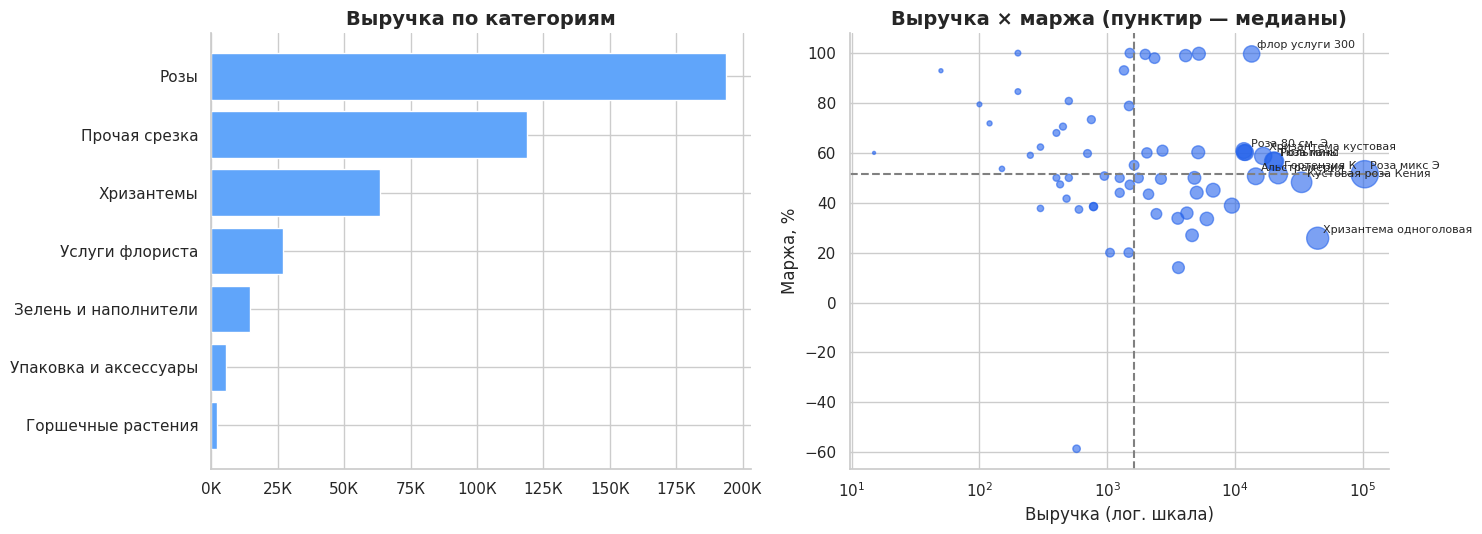

Правый верх — «звёзды» (держим и не даём закончиться). Правый низ — оборотные, но малодоходные: смотрим закупочную цену/наценку.
Левый верх — высокая маржа, но мало продаём: можно выложить на видное место/предлагать к букету.


In [11]:
cat = sales.groupby("категория").agg(выручка=("выручка", "sum"), себестоимость=("себестоимость", "sum"), товаров=("товар", "count"))
cat["маржа_руб"] = cat["выручка"] - cat["себестоимость"]
cat["маржа_%"] = cat["маржа_руб"] / cat["выручка"] * 100
cat["доля_выручки_%"] = cat["выручка"] / cat["выручка"].sum() * 100
cat = cat.sort_values("выручка", ascending=False)
display(cat)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(cat.index[::-1], cat["выручка"][::-1], color="#60A5FA")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_k)); axes[0].set_title("Выручка по категориям")

big = sales[sales["выручка"] > 0].copy()
med_r, med_m = big["выручка"].median(), big["маржа_pct"].median()
axes[1].scatter(big["выручка"], big["маржа_pct"], s=np.sqrt(big["выручка"]) * 1.2, alpha=.6, c="#2563EB")
axes[1].set_xscale("log"); axes[1].axvline(med_r, color="grey", ls="--"); axes[1].axhline(med_m, color="grey", ls="--")
for _, r in big.nlargest(10, "выручка").iterrows():
    axes[1].annotate(r["товар"][:22], (r["выручка"], r["маржа_pct"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("Выручка (лог. шкала)"); axes[1].set_ylabel("Маржа, %")
axes[1].set_title("Выручка × маржа (пунктир — медианы)")
plt.tight_layout(); plt.show()
print("Правый верх — «звёзды» (держим и не даём закончиться). Правый низ — оборотные, но малодоходные: смотрим закупочную цену/наценку.")
print("Левый верх — высокая маржа, но мало продаём: можно выложить на видное место/предлагать к букету.")

## 7. Касса, зарплата, расхождения 💰

Ваша таблица считает «расчётный» остаток кассы и сравнивает с «фактическим». Здесь собираем эту картину: сколько раз и на какую сумму не сходилось, сколько тратим на зарплату от выручки.

Дней с расхождением: 1 из 13
Сумма недостач: -50 ₽ | сумма излишков: 0 ₽ | итого: -50 ₽


,дата,смена,остаток_расчёт,остаток_факт,разница,изъято,внесено,расход_нал,статус
10,2026-10-11,Ирина,1 385.00,1 335.00,-50.00,0.00,0.00,0.00,"❌ НЕДОСТАЧА 50,0 ₽"
1,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


⚠️ Крупные недостачи часто = забыли записать «Изъято из кассы» / расход. Сначала проверьте эти колонки.


,выручка,зп,расход_нал,зп_%_от_выручки,расход_%_от_выручки
месяц,,,,,
2026-10,453 343.00,68 167.15,17 550.00,15.04,3.87


,смен,выручка,зп,выручка_за_смену,зп_%_от_выручки
сотрудник,,,,,
Ирина,9,334 518.00,48 225.90,37 168.67,14.42
Татьяна,4,118 825.00,19 941.25,29 706.25,16.78


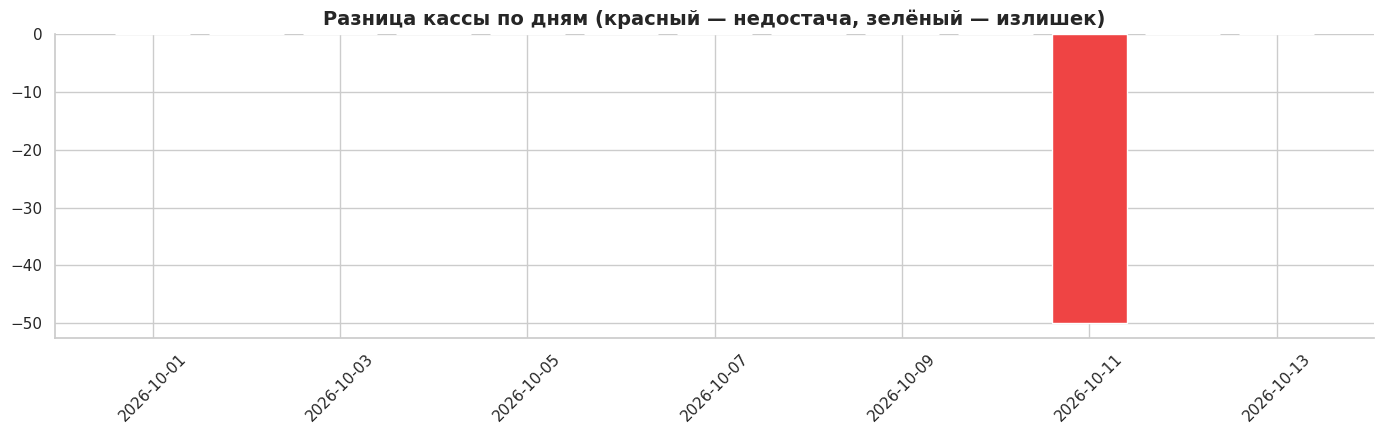

In [12]:
cc = cash.copy()
short = cc.loc[cc["разница"] < 0, "разница"].sum()
over  = cc.loc[cc["разница"] > 0, "разница"].sum()
print(f"Дней с расхождением: {(cc['разница'] != 0).sum()} из {len(cc)}")
print(f"Сумма недостач: {rub(short)} | сумма излишков: {rub(over)} | итого: {rub(short + over)}")

display(cc.loc[cc["разница"].abs() > 0].reindex(cc["разница"].abs().sort_values(ascending=False).index)
          [["дата", "смена", "остаток_расчёт", "остаток_факт", "разница", "изъято", "внесено", "расход_нал", "статус"]].head(10))
print("⚠️ Крупные недостачи часто = забыли записать «Изъято из кассы» / расход. Сначала проверьте эти колонки.")

# Зарплата и расходы от выручки
m = cc.groupby("месяц").agg(выручка=("выручка", "sum"), зп=("зп_начислено", "sum"), расход_нал=("расход_нал", "sum"))
m["зп_%_от_выручки"] = m["зп"] / m["выручка"] * 100
m["расход_%_от_выручки"] = m["расход_нал"] / m["выручка"] * 100
display(m)

# По сотрудникам
e = cash_emp.groupby("сотрудник").agg(смен=("дата", "nunique"), выручка=("выручка", "sum"), зп=("зп", "sum"))
e["выручка_за_смену"] = e["выручка"] / e["смен"]
e["зп_%_от_выручки"] = e["зп"] / e["выручка"] * 100
display(e)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(cc["дата"], cc["разница"], color=np.where(cc["разница"] < 0, "#EF4444", "#10B981"))
ax.set_title("Разница кассы по дням (красный — недостача, зелёный — излишек)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 8. Когда к нам приходят: часы и дни 🕒

Берём **время каждого чека** из «Движения товара». Это нужно, чтобы понять, в какие часы нужен второй флорист, когда ставить акции и когда вывозить свежую поставку.

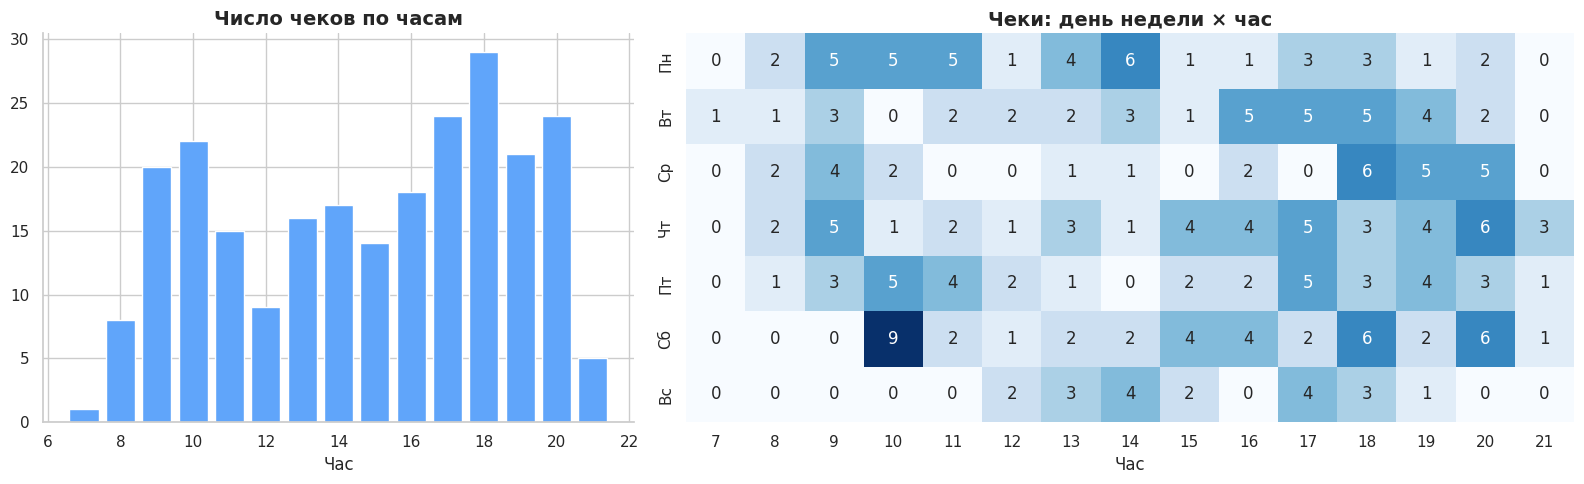

Пиковые часы: [18, 17, 20]. Всего учтено чеков: 243.


In [13]:
rc = checks[checks["есть_время"]].drop_duplicates("док_номер").copy()
rc["час"], rc["день"] = rc["дата"].dt.hour, rc["дата"].dt.dayofweek
heat = rc.pivot_table(index="день", columns="час", values="док_номер", aggfunc="count", fill_value=0)
heat = heat.reindex(index=range(7), columns=range(int(rc["час"].min()), int(rc["час"].max()) + 1), fill_value=0); heat.index = WEEKDAYS

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.5]})
hourly = rc.groupby("час").size()
axes[0].bar(hourly.index, hourly.values, color="#60A5FA"); axes[0].set_title("Число чеков по часам"); axes[0].set_xlabel("Час")
sns.heatmap(heat, cmap="Blues", annot=True, fmt="d", ax=axes[1], cbar=False); axes[1].set_title("Чеки: день недели × час"); axes[1].set_xlabel("Час"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

peak = hourly.sort_values(ascending=False).head(3).index.tolist()
print(f"Пиковые часы: {peak}. Всего учтено чеков: {len(rc)}.")

### 8.1 Оценка суммы каждого чека и сверка по месяцам

В «Движении товара» нет цены продажи, только себестоимость. Но в «Продажи» есть **средняя цена** каждого товара. Умножив количество в чеке на среднюю цену, получаем **оценку** суммы чека (в сумме по всему периоду она равна выручке Бизнес.Ру). Затем сравним по месяцам с вашей кассой: **где разрыв больше — там продажи, которые не попали в программу**.

,чеки Бизнес.Ру (оценка),ваша касса,"Бизнес.Ру, % от кассы"
месяц,,,
2026-10,424 903.00,453 343.00,93.73


Оценка использует среднюю цену за весь период, поэтому по месяцам она приблизительная. Но разница между месяцами — сигнал.

Средний чек ≈ 1 713 ₽ | медианный ≈ 1 257 ₽ | позиций в чеке ≈ 2.1


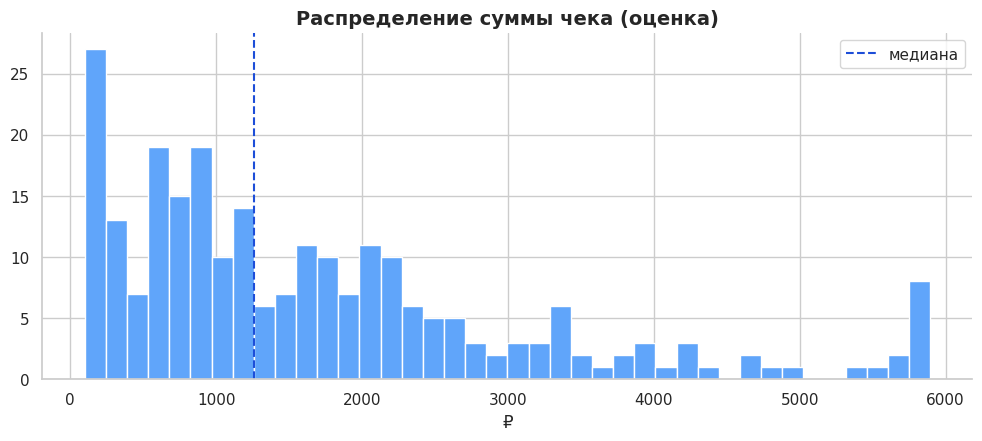

In [14]:
price_map = (sales.set_index("товар")["выручка"] / sales.set_index("товар")["кол_во"]).to_dict()
est = checks.copy()
est["оценка_руб"] = est["кол_во"] * est["товар"].map(price_map)
est["месяц"] = est["дата"].dt.to_period("M").astype(str)

by_m = est.groupby("месяц")["оценка_руб"].sum().to_frame("чеки Бизнес.Ру (оценка)").join(cash.groupby("месяц")["выручка"].sum().rename("ваша касса"))
by_m["Бизнес.Ру, % от кассы"] = by_m["чеки Бизнес.Ру (оценка)"] / by_m["ваша касса"] * 100
display(by_m)
print("Оценка использует среднюю цену за весь период, поэтому по месяцам она приблизительная. Но разница между месяцами — сигнал.")

bills = est.groupby("док_номер").agg(сумма=("оценка_руб", "sum"), позиций=("товар", "nunique"), штук=("кол_во", "sum"))
print(f"\nСредний чек ≈ {rub(bills['сумма'].mean())} | медианный ≈ {rub(bills['сумма'].median())} | позиций в чеке ≈ {bills['позиций'].mean():.1f}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(bills["сумма"].clip(upper=bills["сумма"].quantile(.98)), bins=40, color="#60A5FA")
ax.axvline(bills["сумма"].median(), color="#1D4ED8", ls="--", label="медиана"); ax.legend()
ax.set_title("Распределение суммы чека (оценка)"); ax.set_xlabel("₽"); plt.show()

## 9. Что покупают вместе (корзинный анализ) 🛒

Для каждой пары товаров считаем:
* **Поддержка** — в какой доле чеков они встречаются вместе;
* **Уверенность A→B** — если взяли A, то в скольких % чеков есть и B;
* **Lift** — во сколько раз пара встречается **чаще, чем случайно**. Lift > 1.5 — реальная связка. Lift ≈ 1 — просто оба товара популярны.

Применение: готовые наборы, «к этой розе добавьте эвкалипт», расстановка на витрине.

In [15]:
bk = checks[~checks["категория"].isin(EXCLUDE_FROM_BASKET)]
baskets = bk.groupby("док_номер")["товар"].apply(lambda s: sorted(set(s)))
N = len(baskets)
item_cnt, pair_cnt = Counter(), Counter()
for b in baskets:
    item_cnt.update(b)
    pair_cnt.update(combinations(b, 2))

rows = []
for (a, b), n_ab in pair_cnt.items():
    if n_ab >= MIN_PAIR_COUNT:
        rows.append(dict(товар_A=a, товар_B=b, вместе_чеков=n_ab,
                         поддержка_pct=n_ab / N * 100,
                         уверенность_A_B_pct=n_ab / item_cnt[a] * 100,
                         уверенность_B_A_pct=n_ab / item_cnt[b] * 100,
                         lift=(n_ab / N) / ((item_cnt[a] / N) * (item_cnt[b] / N))))
pairs = pd.DataFrame(rows).sort_values(["lift", "вместе_чеков"], ascending=False) if rows else pd.DataFrame()
svc_share = checks.loc[checks["категория"] == "Услуги флориста", "док_номер"].nunique() / checks["док_номер"].nunique()
print(f"Чеков с товарами: {N}. Из них из одной позиции: {(baskets.map(len) == 1).mean():.0%}. Чеков с услугой флориста: {svc_share:.0%}.")
print(f"Пар, встречающихся ≥{MIN_PAIR_COUNT} раз: {len(pairs)} (из анализа исключено: {', '.join(EXCLUDE_FROM_BASKET)})")
if len(pairs):
    print("\nСамые «сильные» связки (по lift):")
    display(pairs.head(12))
    print("Самые частые пары (по числу чеков):")
    display(pairs.sort_values("вместе_чеков", ascending=False).head(10)[["товар_A", "товар_B", "вместе_чеков", "lift"]])

Чеков с товарами: 241. Из них из одной позиции: 73%. Чеков с услугой флориста: 31%.
Пар, встречающихся ≥5 раз: 13 (из анализа исключено: Услуги флориста)

Самые «сильные» связки (по lift):


,товар_A,товар_B,вместе_чеков,поддержка_pct,уверенность_A_B_pct,уверенность_B_A_pct,lift
0,Оазис,Сумки средние,6,2.49,66.67,100.00,26.78
5,Вакс-флаур,Гортензия К,7,2.90,53.85,41.18,7.63
8,Оазис,Хризантема кустовая,6,2.49,66.67,20.69,5.54
3,Альстрамерия,Гортензия К,6,2.49,28.57,35.29,4.05
6,Вакс-флаур,Хризантема кустовая,6,2.49,46.15,20.69,3.84
4,Альстрамерия,Хризантема кустовая,9,3.73,42.86,31.03,3.56
10,Кустовая роза Кения,Хризантема кустовая,7,2.90,30.43,24.14,2.53
7,Гортензия К,Хризантема кустовая,5,2.07,29.41,17.24,2.44
11,Оазис,Роза микс Э,5,2.07,55.56,7.81,2.09
1,Вакс-флаур,Роза микс Э,6,2.49,46.15,9.38,1.74


Самые частые пары (по числу чеков):


,товар_A,товар_B,вместе_чеков,lift
4,Альстрамерия,Хризантема кустовая,9,3.56
2,Кустовая роза Кения,Роза микс Э,8,1.31
9,Роза микс Э,Хризантема кустовая,8,1.04
10,Кустовая роза Кения,Хризантема кустовая,7,2.53
5,Вакс-флаур,Гортензия К,7,7.63
6,Вакс-флаур,Хризантема кустовая,6,3.84
3,Альстрамерия,Гортензия К,6,4.05
8,Оазис,Хризантема кустовая,6,5.54
0,Оазис,Сумки средние,6,26.78
1,Вакс-флаур,Роза микс Э,6,1.74


## 10. Склад: чего не хватает, а что пора списывать 📦

Цветы — товар с коротким сроком жизни: лишний остаток превращается в списание, а нехватка ходового товара — в потерянную выручку. Для каждого товара считаем:

* **Средние продажи в день** = продано в чеках ÷ дней периода (списания и сборка букетов спросом не считаем);
* **Запас в днях** = остаток ÷ продажи в день;
* и сравниваем со «сроком жизни» категории (настройка `SHELF_LIFE_DAYS`).

In [16]:
period_days = (checks["дата"].max().normalize() - checks["дата"].min().normalize()).days + 1
st = items.merge(sold_checks.rename("продано_чеки").reset_index(), on="товар", how="left")
st["продано_чеки"] = st["продано_чеки"].fillna(0)
st["скрытый_расход"] = st["расход_кол"] - st["продано_чеки"]
st["продаж_в_день"] = st["продано_чеки"] / period_days
st["запас_дней"] = np.where(st["продаж_в_день"] > 0, st["кон_кол"] / st["продаж_в_день"], np.inf)
st["запас_дней_при_полном_расходе"] = np.where(st["расход_кол"] > 0, st["кон_кол"] / (st["расход_кол"] / period_days), np.inf)  # если «скрытый» расход — тоже реальное потребление
st["срок_жизни"] = st["категория"].map(SHELF_LIFE_DAYS).fillna(DEFAULT_SHELF)

def status(r):
    if r["продано_чеки"] > 0 and r["кон_кол"] <= 0:                  return "⛔ Нет в наличии (продавался)"
    if r["кон_кол"] > 0 and r["продано_чеки"] == 0:                  return "💀 Лежит без продаж"
    if r["кон_кол"] > 0 and r["запас_дней"] < MIN_DAYS_COVER:        return "⚠️ Заканчивается"
    if r["кон_кол"] > 0 and r["запас_дней"] > r["срок_жизни"]:       return "🧊 Переизбыток (риск списания)"
    return "✅ Норма"
st["статус"] = st.apply(status, axis=1)

print(f"Период: {period_days} дн.")
display(st["статус"].value_counts().to_frame("товаров"))
cols = ["товар", "категория", "кон_кол", "продаж_в_день", "запас_дней", "запас_дней_при_полном_расходе", "кон_сумма"]
for s_ in ["⛔ Нет в наличии (продавался)", "⚠️ Заканчивается", "🧊 Переизбыток (риск списания)", "💀 Лежит без продаж"]:
    sub = st[st["статус"] == s_].sort_values("продано_чеки", ascending=False)
    if len(sub):
        print(f"\n{s_}  — {len(sub)} шт.")
        display(sub[cols].head(12))
risk_money = st.loc[st["статус"].isin(["🧊 Переизбыток (риск списания)", "💀 Лежит без продаж"]), "кон_сумма"].sum()
print(f"\n💸 Деньги в товаре с риском списания (по себестоимости): {rub(risk_money)}")
print("⚠️ Остаток — по данным программы. Если списания не проводятся, настоящий остаток меньше (цветы завяли, а в системе числятся). "
      "Сверьте с живым пересчётом и проведите инвентаризацию: Склады → Инвентаризации.")

Период: 14 дн.


,товаров
статус,
✅ Норма,264
💀 Лежит без продаж,160
🧊 Переизбыток (риск списания),38
⛔ Нет в наличии (продавался),20
⚠️ Заканчивается,1



⛔ Нет в наличии (продавался)  — 20 шт.


,товар,категория,кон_кол,продаж_в_день,запас_дней,запас_дней_при_полном_расходе,кон_сумма
345,Роза микс Э,Розы,0.00,32.93,0.00,0.00,0.00
342,Роза микс Э,Розы,0.00,32.93,0.00,inf,0.00
343,Роза микс Э,Розы,0.00,32.93,0.00,0.00,0.00
339,Роза микс,Розы,-1.00,13.50,-0.07,-0.12,0.00
341,Роза микс,Розы,0.00,13.50,0.00,0.00,0.00
230,Кустовая роза Кения,Розы,0.00,8.50,0.00,inf,0.00
227,Кустовая роза Кения,Розы,0.00,8.50,0.00,0.00,0.00
228,Кустовая роза Кения,Розы,0.00,8.50,0.00,0.00,0.00
229,Кустовая роза Кения,Розы,0.00,8.50,0.00,0.00,0.00
349,Роза пионовидная Э,Розы,0.00,3.36,0.00,0.00,0.00



⚠️ Заканчивается  — 1 шт.


...


🧊 Переизбыток (риск списания)  — 38 шт.


,товар,категория,кон_кол,продаж_в_день,запас_дней,запас_дней_при_полном_расходе,кон_сумма
344,Роза микс Э,Розы,510.00,32.93,15.49,15.83,54 682.92
16,Альстрамерия,Прочая срезка,52.00,7.00,7.43,5.16,4 699.20
444,Хризантема кустовая,Хризантемы,89.00,5.93,15.01,8.71,9 782.45
104,Гортензия К,Прочая срезка,43.00,3.50,12.29,8.99,9 237.27
90,Георгины,Прочая срезка,69.00,3.43,20.12,5.75,8 280.00
329,Роза 80 см. Э,Розы,125.00,3.07,40.70,39.77,14 043.50
361,Сантини,Прочая срезка,47.00,3.00,15.67,13.71,4 638.60
336,Роза кустовая 60 см. Р,Розы,145.00,2.86,50.75,23.33,14 002.72
72,Вакс-флаур,Прочая срезка,45.00,2.00,22.50,21.00,5 268.00
91,Гербера,Прочая срезка,14.00,1.71,8.17,5.16,1 400.00



💀 Лежит без продаж  — 160 шт.


,товар,категория,кон_кол,продаж_в_день,запас_дней,запас_дней_при_полном_расходе,кон_сумма
6,Азалия микс 13/30,Горшечные растения,2.00,0.00,inf,inf,1 358.40
10,Акалифа подвесная 15/30,Горшечные растения,2.00,0.00,inf,inf,800.00
12,Аквакаркас,Прочая срезка,8.00,0.00,inf,inf,0.00
14,Алое Вера 12/40,Горшечные растения,2.00,0.00,inf,inf,1 104.00
17,Альстрамерия АР,Прочая срезка,7.00,0.00,inf,inf,0.00
18,Амарантус,Прочая срезка,3.00,0.00,inf,inf,804.00
21,Амми,Прочая срезка,14.00,0.00,inf,inf,1 018.00
22,анемон,Прочая срезка,4.00,0.00,inf,inf,400.00
23,Анигозантос,Прочая срезка,4.00,0.00,inf,inf,342.40
26,Антуриум 12/40,Горшечные растения,2.00,0.00,inf,inf,1 550.40



💸 Деньги в товаре с риском списания (по себестоимости): 380 730 ₽
⚠️ Остаток — по данным программы. Если списания не проводятся, настоящий остаток меньше (цветы завяли, а в системе числятся). Сверьте с живым пересчётом и проведите инвентаризацию: Склады → Инвентаризации.


### 10.1 Рекомендация по заказу

Простая и понятная формула (колонка «запас_дней_при_полном_расходе» показывает запас, если «невидимый» расход — это тоже реальное потребление, например сборка букетов): **заказать = (продажи в день × на сколько дней закупаем + страховка) − остаток**. Страховка — запас на «пиковый» день (берём 25% от нормы). Работает хорошо для товаров, которые вы закупаете регулярно.

In [17]:
ORDER_DAYS = 3   # на сколько дней вперёд закупаем (подстройте под частоту поставок)
# не заказываем услуги и товары с отрицательным остатком (там, скорее всего, не оприходована поставка)
order = st[(st["продано_чеки"] > 0) & (st["кон_кол"] >= 0) & (st["категория"] != "Услуги флориста")].copy()
order["норма"] = order["продаж_в_день"] * ORDER_DAYS * 1.25
order["заказать_шт"] = np.ceil((order["норма"] - order["кон_кол"]).clip(lower=0))
order = order[order["заказать_шт"] > 0].sort_values("продано_чеки", ascending=False)
print(f"План закупки на {ORDER_DAYS} дн. (только товары, где остатка не хватает):")
print("Не включены: услуги и товары с минусовым остатком — их сначала нужно исправить в учёте (оприходовать поставку).")
display(order[["товар", "кон_кол", "продаж_в_день", "заказать_шт"]].head(25))

План закупки на 3 дн. (только товары, где остатка не хватает):
Не включены: услуги и товары с минусовым остатком — их сначала нужно исправить в учёте (оприходовать поставку).


,товар,кон_кол,продаж_в_день,заказать_шт
343,Роза микс Э,0.00,32.93,124.00
342,Роза микс Э,0.00,32.93,124.00
345,Роза микс Э,0.00,32.93,124.00
445,Хризантема одноголовая К,48.00,16.71,15.00
341,Роза микс,0.00,13.50,51.00
340,Роза микс,50.00,13.50,1.00
228,Кустовая роза Кения,0.00,8.50,32.00
227,Кустовая роза Кения,0.00,8.50,32.00
229,Кустовая роза Кения,0.00,8.50,32.00
230,Кустовая роза Кения,0.00,8.50,32.00


## 11. Прогноз выручки 🔮

С ~40 днями истории сложные модели (Prophet, нейросети) не нужны и вредны — они «запомнят шум». Используем **честный базовый прогноз**: *медиана выручки по тому же дню недели за последние 5 недель*. И сразу проверяем его на прошлом (**бэктест**) против «наивного» прогноза «как неделю назад». Если наш метод не лучше наивного — доверять ему нельзя.

Ошибка WAPE (меньше — лучше): медиана по дню недели 32.4% | наивный 32.4%


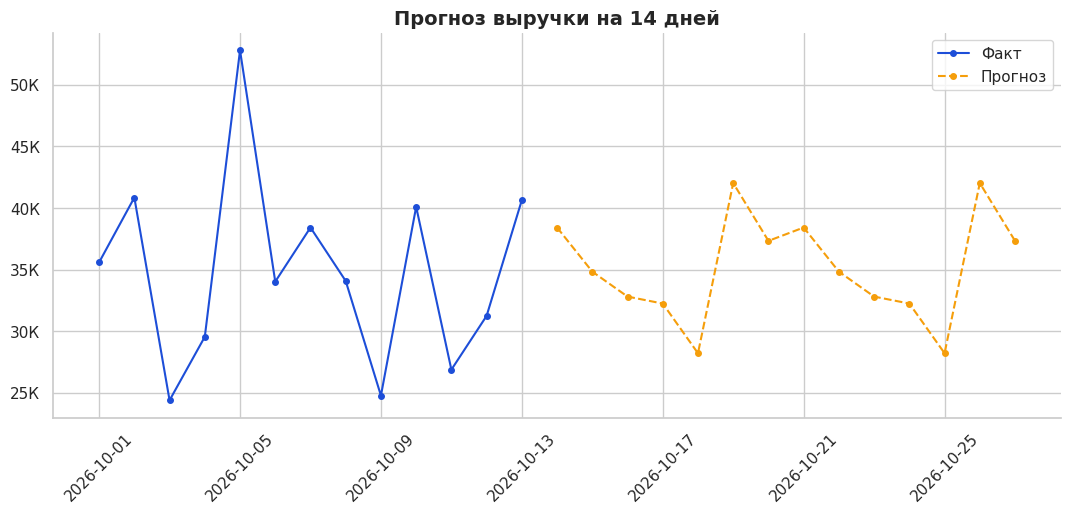

,2026-10-14,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19,2026-10-20,2026-10-21,2026-10-22,2026-10-23,2026-10-24,2026-10-25,2026-10-26,2026-10-27
прогноз,38 415.00,34 835.00,32 812.50,32 247.50,28 217.50,42 020.00,37 331.50,38 415.00,34 835.00,32 812.50,32 247.50,28 217.50,42 020.00,37 331.50
день,Ср,Чт,Пт,Сб,Вс,Пн,Вт,Ср,Чт,Пт,Сб,Вс,Пн,Вт


⚠️ Прогноз НЕ знает про праздники (14 февраля, 8 марта, День матери, 1 сентября): для них смотрите прошлогодние продажи отдельно.


In [18]:
series = cash.set_index("дата")["выручка"].asfreq("D")

def wd_median_forecast(history, target_day, weeks=5):
    """Медиана по тому же дню недели за последние `weeks` недель до target_day."""
    past = [history.get(target_day - pd.Timedelta(days=7 * k)) for k in range(1, weeks + 1)]
    past = [v for v in past if pd.notna(v)]
    return np.median(past) if past else np.nan

# Бэктест на последних 14 днях
test_days = series.index[-14:]
bt = pd.DataFrame({
    "факт": series.loc[test_days],
    "прогноз_медиана": [wd_median_forecast(series[series.index < d], d) for d in test_days],
    "наивный_неделю_назад": [series.get(d - pd.Timedelta(days=7)) for d in test_days],
}).dropna()
wape = lambda a, f: (a - f).abs().sum() / a.sum() * 100
print(f"Ошибка WAPE (меньше — лучше): медиана по дню недели {wape(bt['факт'], bt['прогноз_медиана']):.1f}% | "
      f"наивный {wape(bt['факт'], bt['наивный_неделю_назад']):.1f}%")

# Прогноз вперёд
future = pd.date_range(series.index.max() + pd.Timedelta(days=1), periods=FORECAST_DAYS)
hist = series.copy()
fc = []
for d in future:
    v = wd_median_forecast(hist, d); fc.append(v); hist.loc[d] = v
fc = pd.Series(fc, index=future, name="прогноз")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(series.index[-35:], series.values[-35:], marker="o", ms=4, color="#1D4ED8", label="Факт")
ax.plot(fc.index, fc.values, marker="o", ms=4, ls="--", color="#F59E0B", label="Прогноз")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_k)); ax.legend(); ax.set_title(f"Прогноз выручки на {FORECAST_DAYS} дней"); ax.tick_params(axis="x", rotation=45)
plt.show()
display(fc.to_frame().assign(день=lambda d: d.index.dayofweek.map(dict(enumerate(WEEKDAYS)))).T.round(0))
print("⚠️ Прогноз НЕ знает про праздники (14 февраля, 8 марта, День матери, 1 сентября): для них смотрите прошлогодние продажи отдельно.")

## 12. Необязательно: заказы с доставкой / маркетплейсы (`Отчёт по реализациям`)

В этом отчёте — **документы-реализации** (в вашем файле: заказы от «Яндекс» и частных клиентов). Это не кассовые чеки. Подходит для анализа каналов продаж и наценки по заказам.

In [19]:
def load_realizations(path):
    df = read_csv_smart(path)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    head = df[df["Номер"].notna() & (df["Номер"] != "")].copy()
    head["дата"] = pd.to_datetime(head["Дата"], dayfirst=True, errors="coerce")
    for c in ["Сумма", "Маржа"]:
        head[c] = to_num(head[c])
    return head[["Номер", "дата", "Контрагент", "Сумма", "Маржа"]]

if (DATA_DIR / FILE_REALIZ).exists():
    realiz = load_realizations(DATA_DIR / FILE_REALIZ)
    print(f"Реализаций: {len(realiz)}")
    display(realiz.groupby("Контрагент").agg(заказов=("Номер", "count"), сумма=("Сумма", "sum"), маржа=("Маржа", "sum")))
else:
    print("Файл реализаций не найден — раздел пропущен.")

Реализаций: 0


,заказов,сумма,маржа
Контрагент,,,


## 13. Сохраняем Excel-отчёт 📁

In [20]:
report_path = OUT_DIR / "Отчет_цветочный_магазин.xlsx"
with pd.ExcelWriter(report_path, engine="openpyxl") as xw:
    pd.Series(kpi, name="Значение").to_frame().to_excel(xw, sheet_name="KPI")
    month.to_excel(xw, sheet_name="По месяцам")
    abc_rev.drop(columns=["категория"]).assign(категория=abc_rev["категория"]).to_excel(xw, sheet_name="ABC по выручке", index=False)
    cat.to_excel(xw, sheet_name="Категории")
    cash.to_excel(xw, sheet_name="Касса по дням", index=False)
    st.replace([np.inf], np.nan).to_excel(xw, sheet_name="Склад и остатки", index=False)
    order.to_excel(xw, sheet_name="План закупки", index=False)
    if len(pairs): pairs.to_excel(xw, sheet_name="Связки товаров", index=False)
    fc.to_frame().to_excel(xw, sheet_name="Прогноз")
    hid.sort_values("скрыто_руб", ascending=False).to_excel(xw, sheet_name="Невидимый расход")
    pd.DataFrame({"Проблемы с данными": problems}).to_excel(xw, sheet_name="Проверка данных", index=False)
print(f"✅ Сохранено: {report_path.resolve()}")

✅ Сохранено: D:\Down\21school\bi_muzflowers\output\Отчет_цветочный_магазин.xlsx


## 14. Что делать дальше

1. Раз в неделю выгружайте свежие файлы (список в руководстве) и перезапускайте ноутбук.
2. Добавьте таблицы: **Кассовые чеки**, **Поступления**, **Списания**, **Остатки товаров** — они в 2–3 раза усилят выводы (см. руководство).
3. Когда накопится год истории — подключайте сезонный прогноз (праздники!) и сравнение «год к году».